<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS09/Tugas01_JS09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%pip -q install annoy faiss-cpu hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from annoy import AnnoyIndex
import faiss
import hnswlib

# Kurangi perubahan performa akibat jumlah thread otomatis.
faiss.omp_set_num_threads(2)

UJI_CEPAT = False  # Ubah menjadi True hanya untuk tes awal
JUMLAH_QUERY = 100
K = 5  # 5 tetangga terdekat
METRIK = ["Euclidean", "Cosine"]
KASUS_LENGKAP = [(1_000, 2), (1_000, 5), (1_000_000, 2), (1_000_000, 5)]
KASUS = KASUS_LENGKAP[:2] if UJI_CEPAT else KASUS_LENGKAP

print("Kasus uji:", KASUS)
print("Metrik:", METRIK)
print("Jumlah query per pengujian:", JUMLAH_QUERY)

Kasus uji: [(1000, 2), (1000, 5), (1000000, 2), (1000000, 5)]
Metrik: ['Euclidean', 'Cosine']
Jumlah query per pengujian: 100


In [5]:
def ukur_pencarian(fungsi_cari, query):
    """Rata-rata waktu 1 query dalam milidetik (ms/query)."""
    for vektor in query[:min(5, len(query))]:
        fungsi_cari(vektor)  # warm-up, tidak dihitung

    mulai = time.perf_counter()
    contoh_id = None
    for vektor in query:
        hasil_id = fungsi_cari(vektor)
        if contoh_id is None:
            contoh_id = hasil_id
    durasi_ms = (time.perf_counter() - mulai) * 1000 / len(query)
    return durasi_ms, contoh_id


def uji_annoy(data, query, dimensi, metrik):
    mulai = time.perf_counter()
    jenis_jarak = "euclidean" if metrik == "Euclidean" else "angular"
    indeks = AnnoyIndex(dimensi, jenis_jarak)
    indeks.set_seed(42)
    for i, vektor in enumerate(data):
        indeks.add_item(i, vektor)
    indeks.build(10, n_jobs=2)
    waktu_bangun = time.perf_counter() - mulai

    def cari(q):
        return indeks.get_nns_by_vector(q, K, search_k=250)

    waktu_cari, contoh = ukur_pencarian(cari, query)
    del indeks
    return waktu_bangun, waktu_cari, contoh


def uji_faiss(data, query, dimensi, metrik):
    mulai = time.perf_counter()
    banyak_data = len(data)
    nlist = 16 if banyak_data == 1_000 else 128

    if metrik == "Euclidean":
        pengelompok = faiss.IndexFlatL2(dimensi)
        jenis_jarak = faiss.METRIC_L2
    else:
        pengelompok = faiss.IndexFlatIP(dimensi)
        jenis_jarak = faiss.METRIC_INNER_PRODUCT

    # IndexIVFFlat = pencarian ANN berbasis kelompok/inverted files
    indeks = faiss.IndexIVFFlat(pengelompok, dimensi, nlist, jenis_jarak)
    data_latih = data if banyak_data <= 1_000 else data[::max(1, banyak_data // 15_000)][:15_000].copy()
    indeks.train(data_latih)
    indeks.add(data)
    indeks.nprobe = 8
    waktu_bangun = time.perf_counter() - mulai

    def cari(q):
        _, ids = indeks.search(q.reshape(1, -1), K)
        return ids[0].tolist()

    waktu_cari, contoh = ukur_pencarian(cari, query)
    del indeks, pengelompok
    return waktu_bangun, waktu_cari, contoh


def uji_hnsw(data, query, dimensi, metrik):
    mulai = time.perf_counter()
    jenis_jarak = "l2" if metrik == "Euclidean" else "cosine"
    indeks = hnswlib.Index(space=jenis_jarak, dim=dimensi)
    indeks.init_index(max_elements=len(data), M=8, ef_construction=60, random_seed=42)
    indeks.add_items(data, num_threads=2)
    indeks.set_ef(50)
    waktu_bangun = time.perf_counter() - mulai

    def cari(q):
        ids, _ = indeks.knn_query(q.reshape(1, -1), k=K, num_threads=1)
        return ids[0].tolist()

    waktu_cari, contoh = ukur_pencarian(cari, query)
    del indeks
    return waktu_bangun, waktu_cari, contoh

print("Semua fungsi siap dijalankan.")


Semua fungsi siap dijalankan.


In [6]:
hasil = []
algoritma = {"ANNOY": uji_annoy, "FAISS": uji_faiss, "HNSW": uji_hnsw}

for banyak_data, dimensi in KASUS:
    rng = np.random.default_rng(42 + banyak_data + dimensi)
    data_asli = rng.standard_normal((banyak_data, dimensi)).astype(np.float32)
    query_asli = rng.standard_normal((JUMLAH_QUERY, dimensi)).astype(np.float32)
    nama_kasus = f"{banyak_data}/{dimensi}D"

    for metrik in METRIK:
        # FAISS untuk cosine perlu vektor satuan; gunakan data sama untuk semua pustaka.
        data = np.ascontiguousarray(data_asli.copy())
        query = np.ascontiguousarray(query_asli.copy())
        if metrik == "Cosine":
            faiss.normalize_L2(data)
            faiss.normalize_L2(query)

        for nama_algoritma, fungsi in algoritma.items():
            waktu_bangun, waktu_cari, contoh_id = fungsi(data, query, dimensi, metrik)
            hasil.append({
                "Jumlah Data/Dimensi": nama_kasus,
                "Metric Distance": metrik,
                "Algoritma": nama_algoritma,
                "Waktu Bangun (detik)": round(waktu_bangun, 4),
                "Waktu Cari (ms/query)": round(waktu_cari, 6),
                "Contoh 5 ID Tetangga": str(contoh_id)
            })
            print(f"SELESAI | {nama_kasus:12s} | {metrik:9s} | {nama_algoritma:5s} | "
                  f"Bangun: {waktu_bangun:.3f} detik | Cari: {waktu_cari:.5f} ms/query", flush=True)
            gc.collect()

        del data, query
    del data_asli, query_asli
    gc.collect()

hasil_df = pd.DataFrame(hasil)
print(f"\nPengujian selesai: {len(hasil_df)} pengukuran.")
display(hasil_df)

SELESAI | 1000/2D      | Euclidean | ANNOY | Bangun: 0.022 detik | Cari: 0.04093 ms/query
SELESAI | 1000/2D      | Euclidean | FAISS | Bangun: 0.003 detik | Cari: 0.02255 ms/query
SELESAI | 1000/2D      | Euclidean | HNSW  | Bangun: 0.018 detik | Cari: 0.01597 ms/query
SELESAI | 1000/2D      | Cosine    | ANNOY | Bangun: 0.030 detik | Cari: 0.03400 ms/query
SELESAI | 1000/2D      | Cosine    | FAISS | Bangun: 0.002 detik | Cari: 0.03321 ms/query
SELESAI | 1000/2D      | Cosine    | HNSW  | Bangun: 0.019 detik | Cari: 0.02017 ms/query
SELESAI | 1000/5D      | Euclidean | ANNOY | Bangun: 0.031 detik | Cari: 0.06071 ms/query
SELESAI | 1000/5D      | Euclidean | FAISS | Bangun: 0.026 detik | Cari: 0.08591 ms/query
SELESAI | 1000/5D      | Euclidean | HNSW  | Bangun: 0.089 detik | Cari: 0.04920 ms/query
SELESAI | 1000/5D      | Cosine    | ANNOY | Bangun: 0.088 detik | Cari: 0.11176 ms/query
SELESAI | 1000/5D      | Cosine    | FAISS | Bangun: 0.125 detik | Cari: 0.03711 ms/query
SELESAI | 

,Jumlah Data/Dimensi,Metric Distance,Algoritma,Waktu Bangun (detik),Waktu Cari (ms/query),Contoh 5 ID Tetangga
0,1000/2D,Euclidean,ANNOY,0.0216,0.040928,"[450, 255, 69, 485, 900]"
1,1000/2D,Euclidean,FAISS,0.0034,0.022552,"[450, 255, 69, 485, 900]"
2,1000/2D,Euclidean,HNSW,0.0178,0.015975,"[450, 255, 69, 485, 900]"
3,1000/2D,Cosine,ANNOY,0.0299,0.033997,"[596, 390, 914, 278, 493]"
4,1000/2D,Cosine,FAISS,0.0019,0.033210,"[596, 390, 914, 278, 493]"
5,1000/2D,Cosine,HNSW,0.0190,0.020174,"[596, 390, 914, 278, 493]"
6,1000/5D,Euclidean,ANNOY,0.0310,0.060705,"[280, 540, 855, 160, 99]"
7,1000/5D,Euclidean,FAISS,0.0262,0.085914,"[280, 540, 855, 160, 99]"
8,1000/5D,Euclidean,HNSW,0.0891,0.049199,"[280, 540, 855, 160, 99]"
9,1000/5D,Cosine,ANNOY,0.0879,0.111763,"[19, 160, 810, 734, 280]"


In [7]:
urutan_kasus = [f"{n}/{d}D" for n, d in KASUS]

for metrik in METRIK:
    data_metrik = hasil_df[hasil_df["Metric Distance"] == metrik]
    print(f"\n=== METRIK {metrik.upper()} — WAKTU PENCARIAN (ms/query) ===")
    tabel_cari = data_metrik.pivot(
        index="Jumlah Data/Dimensi", columns="Algoritma", values="Waktu Cari (ms/query)"
    ).reindex(index=urutan_kasus, columns=["ANNOY", "FAISS", "HNSW"])
    display(tabel_cari.round(6))

    print(f"=== METRIK {metrik.upper()} — WAKTU MEMBANGUN INDEKS (detik) ===")
    tabel_bangun = data_metrik.pivot(
        index="Jumlah Data/Dimensi", columns="Algoritma", values="Waktu Bangun (detik)"
    ).reindex(index=urutan_kasus, columns=["ANNOY", "FAISS", "HNSW"])
    display(tabel_bangun.round(4))


=== METRIK EUCLIDEAN — WAKTU PENCARIAN (ms/query) ===


Algoritma,ANNOY,FAISS,HNSW
Jumlah Data/Dimensi,,,
1000/2D,0.040928,0.022552,0.015975
1000/5D,0.060705,0.085914,0.049199
1000000/2D,0.119701,0.852452,0.026978
1000000/5D,0.088213,0.609820,0.066533


=== METRIK EUCLIDEAN — WAKTU MEMBANGUN INDEKS (detik) ===


Algoritma,ANNOY,FAISS,HNSW
Jumlah Data/Dimensi,,,
1000/2D,0.0216,0.0034,0.0178
1000/5D,0.0310,0.0262,0.0891
1000000/2D,25.9083,0.3479,32.9986
1000000/5D,20.8703,0.2355,50.0801



=== METRIK COSINE — WAKTU PENCARIAN (ms/query) ===


Algoritma,ANNOY,FAISS,HNSW
Jumlah Data/Dimensi,,,
1000/2D,0.033997,0.033210,0.020174
1000/5D,0.111763,0.037110,0.028772
1000000/2D,0.090852,1.117560,0.033393
1000000/5D,0.109892,1.162355,0.043440


=== METRIK COSINE — WAKTU MEMBANGUN INDEKS (detik) ===


Algoritma,ANNOY,FAISS,HNSW
Jumlah Data/Dimensi,,,
1000/2D,0.0299,0.0019,0.0190
1000/5D,0.0879,0.1246,0.0391
1000000/2D,76.4060,1.4460,36.2283
1000000/5D,25.8447,0.8766,47.6277


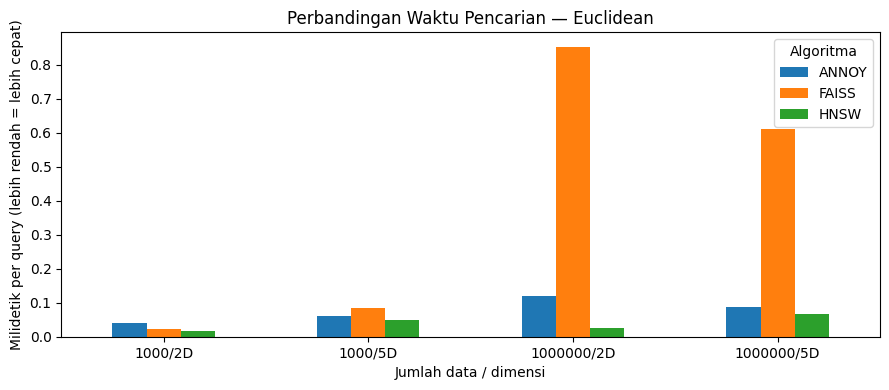

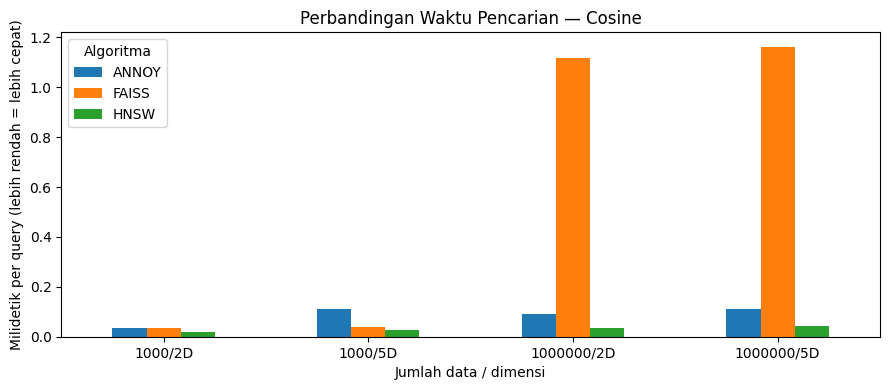

In [8]:
for metrik in METRIK:
    tabel = (hasil_df[hasil_df["Metric Distance"] == metrik]
             .pivot(index="Jumlah Data/Dimensi", columns="Algoritma", values="Waktu Cari (ms/query)")
             .reindex(index=urutan_kasus, columns=["ANNOY", "FAISS", "HNSW"]))
    ax = tabel.plot(kind="bar", figsize=(9, 4))
    ax.set_title(f"Perbandingan Waktu Pencarian — {metrik}")
    ax.set_xlabel("Jumlah data / dimensi")
    ax.set_ylabel("Milidetik per query (lebih rendah = lebih cepat)")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

In [9]:
for metrik in METRIK:
    print(f"\nMETRIK {metrik.upper()}")
    for kasus in urutan_kasus:
        potongan = hasil_df[(hasil_df["Metric Distance"] == metrik) &
                            (hasil_df["Jumlah Data/Dimensi"] == kasus)]
        paling_cepat = potongan.sort_values("Waktu Cari (ms/query)").iloc[0]
        print(f"- {kasus}: pencarian tercepat = {paling_cepat['Algoritma']} "
              f"({paling_cepat['Waktu Cari (ms/query)']:.6f} ms/query)")


METRIK EUCLIDEAN
- 1000/2D: pencarian tercepat = HNSW (0.015975 ms/query)
- 1000/5D: pencarian tercepat = HNSW (0.049199 ms/query)
- 1000000/2D: pencarian tercepat = HNSW (0.026978 ms/query)
- 1000000/5D: pencarian tercepat = HNSW (0.066533 ms/query)

METRIK COSINE
- 1000/2D: pencarian tercepat = HNSW (0.020174 ms/query)
- 1000/5D: pencarian tercepat = HNSW (0.028772 ms/query)
- 1000000/2D: pencarian tercepat = HNSW (0.033393 ms/query)
- 1000000/5D: pencarian tercepat = HNSW (0.043440 ms/query)


In [10]:
hasil_df.to_csv("hasil_ann_lab1_lengkap.csv", index=False)
for metrik in METRIK:
    label = metrik.lower()
    potongan = hasil_df[hasil_df["Metric Distance"] == metrik]
    tabel = (potongan.pivot(index="Jumlah Data/Dimensi", columns="Algoritma", values="Waktu Cari (ms/query)")
             .reindex(index=urutan_kasus, columns=["ANNOY", "FAISS", "HNSW"]))
    tabel.to_csv(f"hasil_ann_{label}_pencarian.csv")
print("File CSV berhasil disimpan di sesi Colab.")

File CSV berhasil disimpan di sesi Colab.
